# Fixed-width window FFD + rolling Z — 2023 → 2025, ADF health check

Continues `ffd-z-plot1.ipynb` (which stops at 2022-12-31). Same FFD; only the rolling Z is shown.

| Item | Setting |
|---|---|
| Method | Fixed-width window FFD on `log(close)`, daily |
| τ / d / FFD window | **1e-4 / 0.25 / 445 bars** (unchanged, chosen on train 2021–2023) |
| Z reference | **Rolling 445 bars (= FFD window)**: μ_t, σ_t from the last 445 FFD bars up to t (ddof = 0). Same anchor and 60-bar burn-in as `ffd-z-plot1.ipynb`, so the window is already full for every asset by 2023 |
| Plot range | **2023-01-01 → 2025-12-31**. FFD and Z are computed from 2019 data, causally, so values match `ffd-z-plot1.ipynb` where the two overlap |
| Train / test | 2023 is the last train year. **2024–2025 are test years.** This notebook is the ADF health check from the maintenance rule (README §3). It does not re-select d |

ADF settings: `regression='c', maxlag=1, autolag=None`, threshold p < 0.01 (as in `ffd-d-sweep.ipynb`), with p < 0.05 shown for reference.

Maintenance rule: one failing year changes nothing. Only a **persistent** failure (the 2–3-year window fails, or two years in a row fail) is a reason to consider raising d at the yearly review.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import adfuller

DATA = Path('../../data')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
TAU, D = 1e-4, 0.25
Z_MIN = 60
PLOT_START, PLOT_END = '2023-01-01', '2025-12-31'
ALPHA_STRICT, ALPHA = 0.01, 0.05

def ffd_weights(d, tau=TAU):
    w = [1.0]
    while True:
        k = len(w)
        nxt = -w[-1] * (d - k + 1) / k
        if abs(nxt) < tau:
            return np.asarray(w)
        w.append(nxt)

def ffd(log_close, d=D, tau=TAU):
    w = ffd_weights(d, tau)
    y = np.full(len(log_close), np.nan)
    y[len(w) - 1:] = np.convolve(log_close.values, w, mode='valid')
    return pd.Series(y, index=log_close.index)

def load(sym):
    df = pd.read_parquet(DATA / sym / f'{sym}-sorted-1d.parquet')
    ts = pd.to_datetime(df['timestamp'])
    ts = ts.dt.tz_convert(None) if ts.dt.tz is not None else ts
    assert ts.is_monotonic_increasing and ts.is_unique
    return df.set_axis(ts)['close']

W = len(ffd_weights(D)); W

445

In [2]:
frames = {}
for s in ASSETS:
    close = load(s).loc[:PLOT_END]                  # causal: nothing after PLOT_END is used
    f = ffd(np.log(close))
    fa = f.loc[f.first_valid_index():]
    r = fa.rolling(W, min_periods=Z_MIN)
    frames[s] = pd.DataFrame({'close': close, 'ffd': f, 'z_roll': (fa - r.mean()) / r.std(ddof=0)})

pd.DataFrame({s: {'rolling window full from': frames[s].ffd.dropna().index[W - 1].date(),
                  'last bar': frames[s].index[-1].date(),
                  'bars 2023–2025': int(frames[s].loc[PLOT_START:].shape[0])} for s in ASSETS}).T

,rolling window full from,last bar,bars 2023–2025
BTC,2021-06-07,2025-12-31,1096
ETH,2021-06-07,2025-12-31,1096
QQQ,2022-07-13,2025-12-31,752
XAUUSD,2022-06-10,2025-12-31,774


## Price / FFD / rolling Z (2023 → 2025)

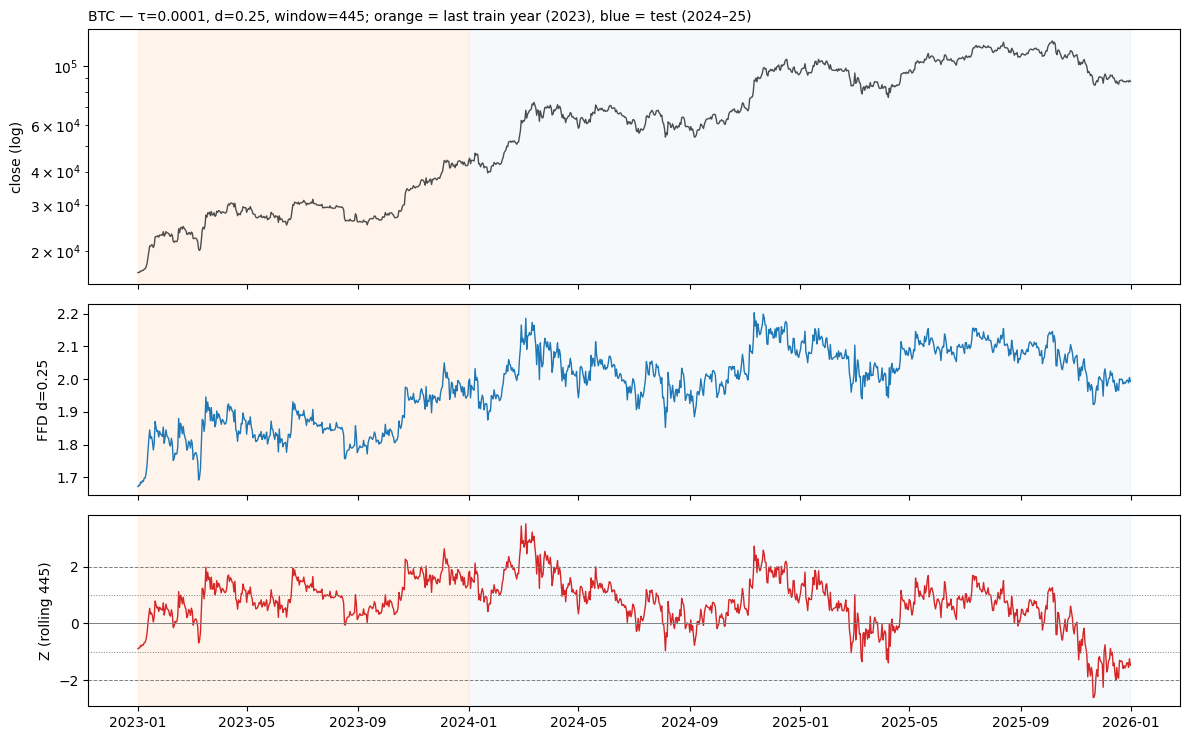

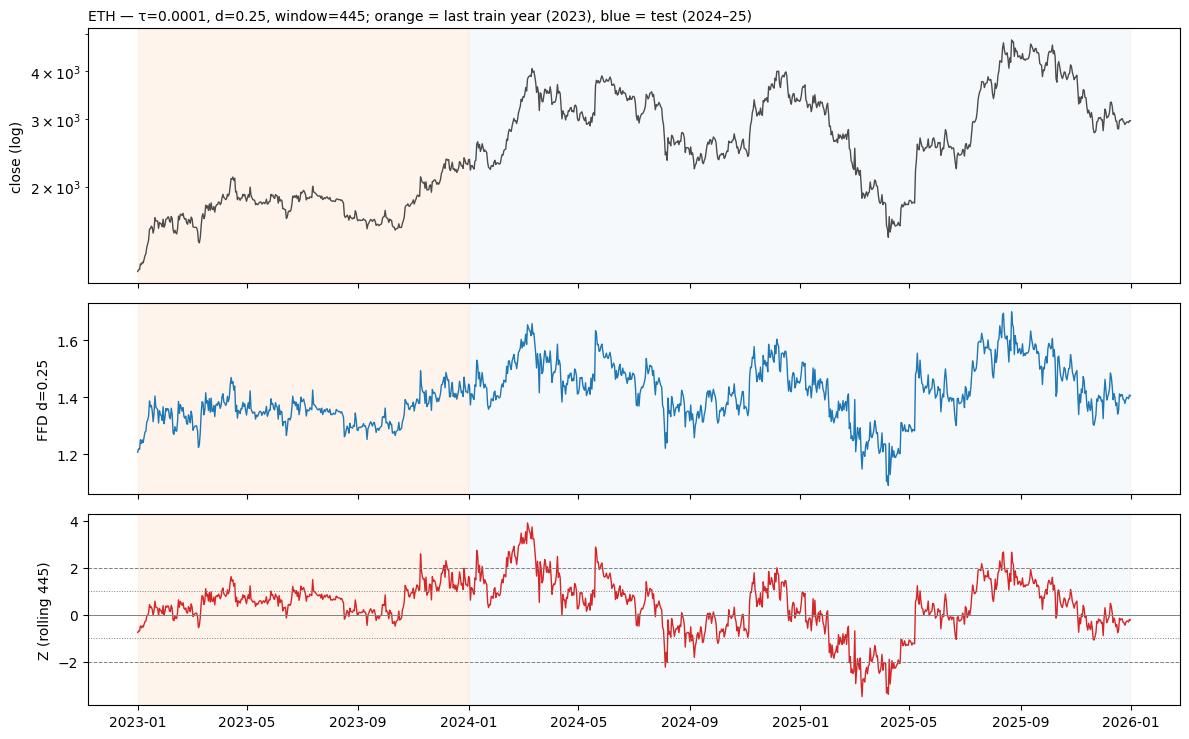

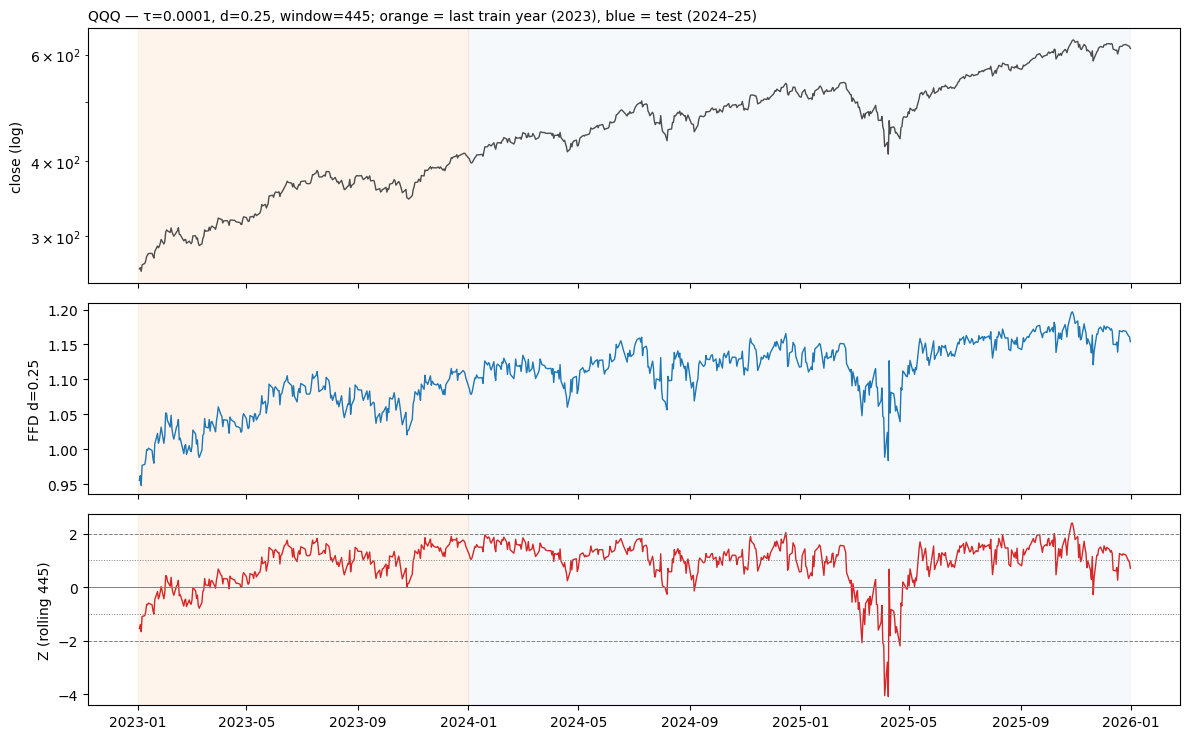

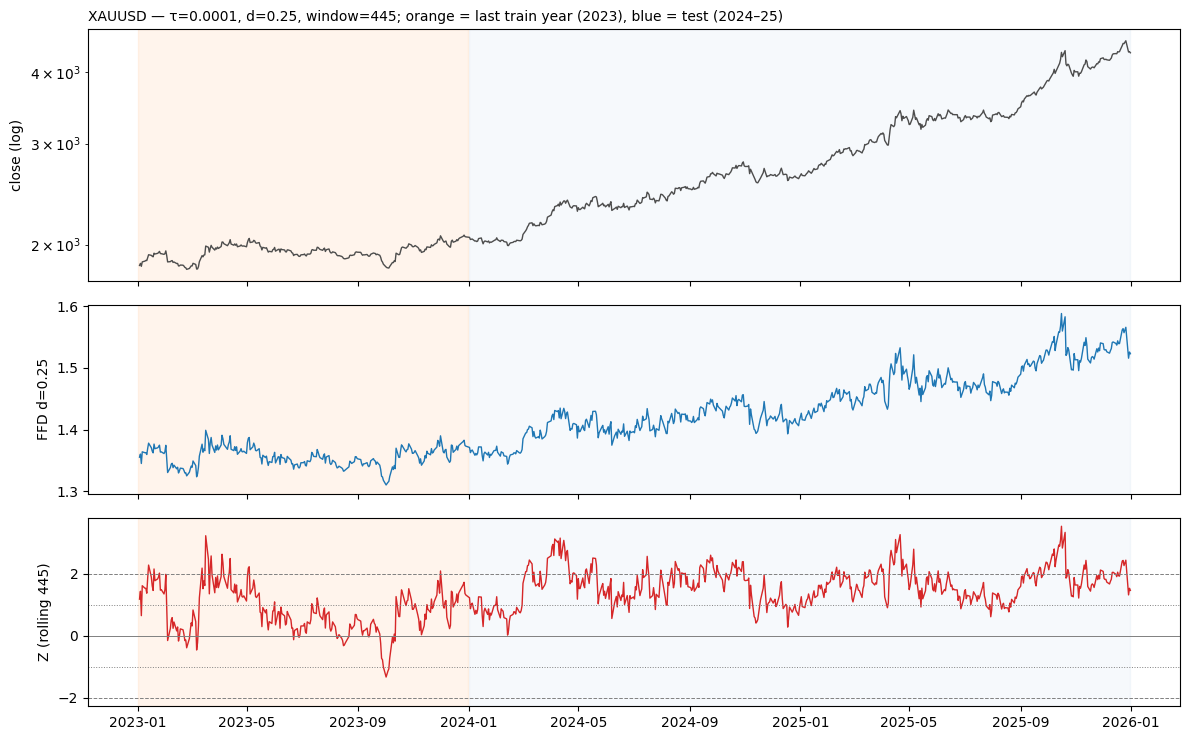

In [3]:
for s in ASSETS:
    df = frames[s].loc[PLOT_START:]
    fig, ax = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True,
                           gridspec_kw={'height_ratios': [2, 1.5, 1.5]})
    ax[0].plot(df.index, df.close, color='0.3', lw=1); ax[0].set_yscale('log'); ax[0].set_ylabel('close (log)')
    ax[1].plot(df.index, df.ffd, color='tab:blue', lw=1); ax[1].set_ylabel(f'FFD d={D}')
    ax[2].plot(df.index, df.z_roll, color='tab:red', lw=1); ax[2].set_ylabel(f'Z (rolling {W})')
    for lvl, ls in [(0, '-'), (1, ':'), (-1, ':'), (2, '--'), (-2, '--')]:
        ax[2].axhline(lvl, color='0.5', lw=0.7, ls=ls)
    for a in ax:
        a.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-31'), color='tab:orange', alpha=0.08)
        a.axvspan(pd.Timestamp('2024-01-01'), pd.Timestamp(PLOT_END), color='tab:blue', alpha=0.04)
    ax[0].set_title(f'{s} — τ={TAU:g}, d={D}, window={W}; orange = last train year (2023), blue = test (2024–25)',
                    loc='left', fontsize=10)
    plt.tight_layout(); plt.show()

## ADF health check on FFD (d = 0.25, τ = 1e-4)

ADF runs on the **FFD series**, not on Z. Z is FFD rescaled by its rolling μ/σ, so it is not a test of d.

Windows: each single year, each 2-year window, the full 2023–2025, and the train window 2021–2023 for reference.

In [4]:
WINDOWS = {'train 2021–23': ('2021', '2023'),
           '2023': ('2023', '2023'), '2024': ('2024', '2024'), '2025': ('2025', '2025'),
           '2023–24': ('2023', '2024'), '2024–25': ('2024', '2025'), '2023–25': ('2023', '2025')}
rows = []
for s in ASSETS:
    for name, (a, b) in WINDOWS.items():
        y = frames[s].ffd.loc[a:b].dropna()
        stat, p, _, _, crit = adfuller(y, maxlag=1, regression='c', autolag=None)
        rows.append({'asset': s, 'window': name, 'n': len(y), 'ADF stat': round(stat, 2),
                     'crit 1%': round(crit['1%'], 2), 'p': round(p, 4),
                     'pass 1%': p < ALPHA_STRICT, 'pass 5%': p < ALPHA})
adf = pd.DataFrame(rows).set_index(['asset', 'window'])
adf

n  ADF stat  crit 1%       p  pass 1%  pass 5%
asset  window                                                          
BTC    train 2021–23  1095     -3.57    -3.44  0.0064     True     True
       2023            365     -3.28    -3.45  0.0159    False     True
       2024            366     -3.08    -3.45  0.0279    False     True
       2025            365     -3.27    -3.45  0.0161    False     True
       2023–24         731     -3.02    -3.44  0.0330    False     True
       2024–25         731     -4.31    -3.44  0.0004     True     True
       2023–25        1096     -3.63    -3.44  0.0052     True     True
ETH    train 2021–23  1095     -4.03    -3.44  0.0013     True     True
       2023            365     -4.28    -3.45  0.0005     True     True
       2024            366     -3.44    -3.45  0.0096     True     True
       2025            365     -2.65    -3.45  0.0823    False    False
       2023–24         731     -4.19    -3.44  0.0007     True     True
       2024–25         731     -4.05    -3.44  0.0012     True     True
       2023–25        1096     -4.87    -3.44  0.0000     True     True
QQQ    train 2021–23   753     -3.73    -3.44  0.0037     True     True
       2023            250     -2.95    -3.46  0.0396    False     True
       2024            252     -4.48    -3.46  0.0002     True     True
       2025            250     -2.29    -3.46  0.1751    False    False
       2023–24         502     -3.49    -3.44  0.0083     True     True
       2024–25         502     -3.90    -3.44  0.0020     True     True
       2023–25         752     -3.66    -3.44  0.0047     True     True
XAUUSD train 2021–23   773     -5.25    -3.44  0.0000     True     True
       2023            257     -3.70    -3.46  0.0041     True     True
       2024            259     -2.74    -3.46  0.0670    False    False
       2025            258     -2.62    -3.46  0.0883    False    False
       2023–24         516     -2.52    -3.44  0.1100    False    False
       2024–25         517     -2.05    -3.44  0.2637    False    False
       2023–25         774     -1.65    -3.44  0.4577    False    False

In [5]:
# p-values at a glance
adf['p'].unstack('window')[list(WINDOWS)].round(3)

window,train 2021–23,2023,2024,2025,2023–24,2024–25,2023–25
asset,,,,,,,
BTC,0.006,0.016,0.028,0.016,0.033,0.000,0.005
ETH,0.001,0.000,0.010,0.082,0.001,0.001,0.000
QQQ,0.004,0.040,0.000,0.175,0.008,0.002,0.005
XAUUSD,0.000,0.004,0.067,0.088,0.110,0.264,0.458


## Maintenance-rule verdict (persistent failure?)

In [6]:
def verdict(s, alpha):
    p = adf.loc[s, 'p']
    yearly_fail = [y for y in ['2023', '2024', '2025'] if p[y] >= alpha]
    two_in_row = any(a in yearly_fail and b in yearly_fail for a, b in [('2023', '2024'), ('2024', '2025')])
    multi_fail = [w for w in ['2023–24', '2024–25', '2023–25'] if p[w] >= alpha]
    return {'single years failing': ', '.join(yearly_fail) or '—',
            'two years in a row fail': two_in_row,
            '2–3-year windows failing': ', '.join(multi_fail) or '—',
            'persistent → review d': two_in_row or bool(multi_fail)}

# the maintenance rule does not fix the ADF threshold; show both
pd.concat({f'p ≥ {a}': pd.DataFrame({s: verdict(s, a) for s in ASSETS}).T for a in [ALPHA_STRICT, ALPHA]})

single years failing two years in a row fail  \
p ≥ 0.01 BTC        2023, 2024, 2025                    True   
         ETH                    2025                   False   
         QQQ              2023, 2025                   False   
         XAUUSD           2024, 2025                    True   
p ≥ 0.05 BTC                       —                   False   
         ETH                    2025                   False   
         QQQ                    2025                   False   
         XAUUSD           2024, 2025                    True   

                  2–3-year windows failing persistent → review d  
p ≥ 0.01 BTC                       2023–24                  True  
         ETH                             —                 False  
         QQQ                             —                 False  
         XAUUSD  2023–24, 2024–25, 2023–25                  True  
p ≥ 0.05 BTC                             —                 False  
         ETH                             —                 False  
         QQQ                             —                 False  
         XAUUSD  2023–24, 2024–25, 2023–25                  True

### Findings (2023 → 2025, d = 0.25, τ = 1e-4)

- **XAUUSD: d = 0.25 does not hold.** FFD trends upward through 2024–2025 with gold's rally. ADF fails on every 2–3-year window (2023–24 p = 0.11, 2024–25 p = 0.26, 2023–25 p = 0.46) and in both 2024 and 2025. This is a persistent failure at either threshold, so per the maintenance rule d should be reviewed for gold at the yearly review.
- **BTC is flagged only by the 1% threshold.** Single years sit at p = 0.016–0.028 and 2023–24 at p = 0.033, much like during train (single train years also scored 0.02–0.04). The 2024–25 and 2023–25 windows pass clearly (p ≤ 0.005). At 5% nothing fails. One-year ADF at 1% is too strict to read as a failure.
- **ETH and QQQ: single-year dips only** (ETH 2025 p = 0.08, QQQ 2025 p = 0.18). All 2–3-year windows pass at 1%. Not persistent, so no change.
- **Rolling Z does not fix a trending FFD.** Gold's rolling-445 Z stays at about +1 to +2 through 2024–25 (25–27% of days above 2), because the trend keeps outrunning the window.
- **Open:** the maintenance rule does not say which ADF threshold to use. 1% on single years flags BTC on noise; 5% flags only gold.
- 2024–2025 are test years. d is not re-selected here. Any review of gold's d must use only data available at the review date.

## Rolling Z summary by year

In [7]:
summary = pd.concat({s: frames[s].z_roll.loc[PLOT_START:].groupby(frames[s].loc[PLOT_START:].index.year).agg(
    mean='mean', std='std', pct_abs_gt2=lambda z: (z.dropna().abs() > 2).mean() * 100) for s in ASSETS})
summary.round(2)

mean   std  pct_abs_gt2
       timestamp                         
BTC    2023       0.92  0.64         3.01
       2024       1.12  0.82        14.75
       2025       0.25  0.95         1.37
ETH    2023       0.60  0.56         1.10
       2024       0.77  1.16        14.21
       2025      -0.11  1.29        13.42
QQQ    2023       0.70  0.76         0.00
       2024       1.22  0.41         0.40
       2025       0.83  1.02         4.40
XAUUSD 2023       0.81  0.77         5.84
       2024       1.55  0.64        27.03
       2025       1.72  0.50        25.19